# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** MEHTAB AHMED
- **Student ID:** 023-24-0285
- **Section:** H
- **GitHub:** https://github.com/mehtabahmeddev/MACHINE-LEARNING
- **Kaggle:**https://www.kaggle.com/mehtabahmed3201
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [2]:
# YOUR CODE HERE
# 1.
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
})

# 2. Print shape, missing values, duplicates, and gender counts
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nGender Counts:\n", df['Gender'].value_counts())

# # 3. Show describe() for Age, Income, and Spending
print("\nSummary Statistics:\n", df[['Age', 'Income', 'Spending']].describe())


Dataset Shape: (200, 5)

Missing Values:
 CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate Rows: 0

Gender Counts:
 Gender
Female    112
Male       88
Name: count, dtype: int64

Summary Statistics:
               Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

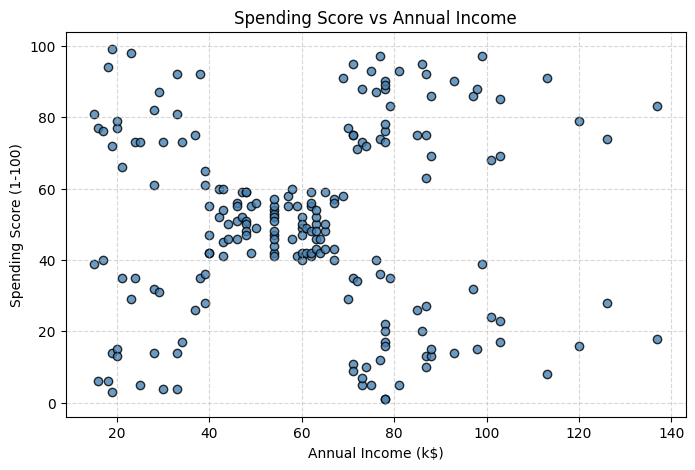

In [3]:
# YOUR CODE HERE
plt.figure(figsize=(8, 5))
plt.scatter(df['Income'], df['Spending'], color='steelblue', edgecolors='k', alpha=0.8)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending Score vs Annual Income')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



Looking at the scatter plot of Spending Score against Annual Income, the 200 customers naturally separate into 5 distinct clusters. There is one large, dense group in the center (Income around $40k–$70k and Spending around 40–60). Surrounding this middle group are four well-separated corner groups representing low-income/low-spending, low-income/high-spending, high-income/low-spending, and high-income/high-spending customers. This visual pattern gives us a strong clue that $K = 5$ will be the ideal number of clusters.

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a)
Low income, low spending: Customers earning around 15k–40k with low spending scores 

Low income, high spending: Customers earning around 15k–40k with high spending scores 

Medium income, medium spending: The largest dense group in the middle earning around 40k–70k with moderate spending scores 

High income, low spending: Customers earning above 70k (up to 137k) with low spending scores 

High income, high spending: Customers earning above 70k (up to 137k) with high spending scores 

(b)
Clustering is unsupervised learning, meaning there is no target column  or true labels to compare predictions against. Because there are no correct labels, we cannot compute accuracy or perform a train/test split; instead, we judge clusters using distances inertia, silhouette scores, plots, and common sense.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [4]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
centroids = np.array([4.0, 11.0])

iteration = 0
while True:
    iteration += 1
    
    # 1. Compute distance matrix (shape 9x2) and assign clusters
    dist = np.abs(x[:, None] - centroids[None, :])
    labels = dist.argmin(axis=1)
    
    # 2. Update centroids
    new_centroids = np.array([x[labels == k].mean() for k in range(2)])
    
    print(f"Iteration {iteration}:")
    print("  Cluster 0 (C1):", x[labels == 0].astype(int).tolist())
    print("  Cluster 1 (C2):", x[labels == 1].astype(int).tolist())
    print("  New Centroids :", new_centroids)
    
    # 3. Check convergence
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

# Calculate final inertia
inertia = np.sum((x - centroids[labels]) ** 2)

print("\nFinal Centroids:", centroids)
print("Final Inertia  :", inertia)


Iteration 1:
  Cluster 0 (C1): [2, 4, 3]
  Cluster 1 (C2): [10, 12, 20, 30, 11, 25]
  New Centroids : [ 3. 18.]
Iteration 2:
  Cluster 0 (C1): [2, 4, 10, 3]
  Cluster 1 (C2): [12, 20, 30, 11, 25]
  New Centroids : [ 4.75 19.6 ]
Iteration 3:
  Cluster 0 (C1): [2, 4, 10, 12, 3, 11]
  Cluster 1 (C2): [20, 30, 25]
  New Centroids : [ 7. 25.]
Iteration 4:
  Cluster 0 (C1): [2, 4, 10, 12, 3, 11]
  Cluster 1 (C2): [20, 30, 25]
  New Centroids : [ 7. 25.]

Final Centroids: [ 7. 25.]
Final Inertia  : 150.0


### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [5]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
        
    centroids = np.asarray(init_centroids, dtype=float).copy()
    if centroids.ndim == 1:
        centroids = centroids[:, None]
        
    K = len(centroids)
    
    for i in range(1, max_iter + 1):
        # Compute Euclidean distance to every centroid: shape (N, K)
        dist = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        labels = dist.argmin(axis=1)
        
        # Update each centroid
        new_centroids = np.array([
            X[labels == k].mean(axis=0) if np.any(labels == k) else centroids[k]
            for k in range(K)
        ])
        
        if np.allclose(new_centroids, centroids, rtol=0, atol=1e-12):
            centroids = new_centroids
            break
        centroids = new_centroids
        
    # Compute inertia (sum of squared Euclidean distances)
    inertia = np.sum(((X - centroids[labels]) ** 2).sum(axis=1))
    
    return labels, centroids.squeeze(), inertia, i

# Test on Example 1
ex1_labels, ex1_centroids, ex1_inertia, ex1_iters = my_kmeans(x, [4.0, 11.0])
print("Example 1 Test:")
print("  Centroids :", ex1_centroids)
print("  Inertia   :", ex1_inertia)
print("  Iterations:", ex1_iters)

Example 1 Test:
  Centroids : [ 7. 25.]
  Inertia   : 150.0
  Iterations: 4


In [6]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values
init_5 = X2[:5].copy()

# Run custom K-Means
my_labels, my_centers, my_inertia, my_iters = my_kmeans(X2, init_5)

# Run scikit-learn KMeans
sk_model = KMeans(n_clusters=5, init=init_5, n_init=1, tol=0, algorithm='lloyd', random_state=SEED)
sk_model.fit(X2)

print("My K-Means Inertia      :", my_inertia)
print("Scikit-learn Inertia    :", sk_model.inertia_)
print("Inertia Difference      :", abs(my_inertia - sk_model.inertia_))

print("\nMy K-Means Centroids:\n", np.round(my_centers, 4))
print("\nScikit-learn Centroids:\n", np.round(sk_model.cluster_centers_, 4))

My K-Means Inertia      : 44448.45544793371
Scikit-learn Inertia    : 44448.45544793371
Inertia Difference      : 0.0

My K-Means Centroids:
 [[26.3043 20.913 ]
 [25.7273 79.3636]
 [88.2    17.1143]
 [86.5385 82.1282]
 [55.2963 49.5185]]

Scikit-learn Centroids:
 [[26.3043 20.913 ]
 [25.7273 79.3636]
 [88.2    17.1143]
 [86.5385 82.1282]
 [55.2963 49.5185]]


C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SINDH\AppData\Local\Programs\Python\Pytho

**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a)
With starting centroids 4 and 11, point 10 was closer to 11 ($\vert{}10 - 11\vert{} = 1$) than to 4 ($\vert{}10 - 4\vert{} = 6$), so it was placed in C2 in Iteration 1. After Iteration 1 updated the centroids, C1 moved from 4 to 3.0 and C2 moved from 11 to 18.0. In Iteration 2, point 10 became closer to C1 ($\vert{}10 - 3\vert{} = 7$) than to C2 ($\vert{}10 - 18\vert{} = 8$), so it moved to C1

(b)
The loop stops when convergence is reached—meaning no points change clusters and the centroids stop moving (np.allclose(new_c, c)). Stopping is guaranteed because there are only a finite number of possible cluster assignments for $N$ points, and each assign/update step reduces (or keeps equal) the inertia, so it cannot loop forever. However, depending on where the initial centroids start, it can get stuck in a local minimum instead of finding the global best clustering.


(c)Yes, my function matched scikit-learn's KMeans identically in both inertia (44448.4554, difference 0.0) and all 5 cluster centroids, because both started from the same 5 rows, used Lloyd's assign/update steps, and ran until zero centroid movement


---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

 K   Inertia  Silhouette
 2 181363.60      0.2969
 3 106348.37      0.4676
 4  73679.79      0.4932
 5  44448.46      0.5539
 6  37233.81      0.5398
 7  30241.34      0.5288
 8  25036.42      0.4548
 9  21916.79      0.4561
10  20072.07      0.4411

Best K by highest Silhouette score: K = 5 (0.5539)


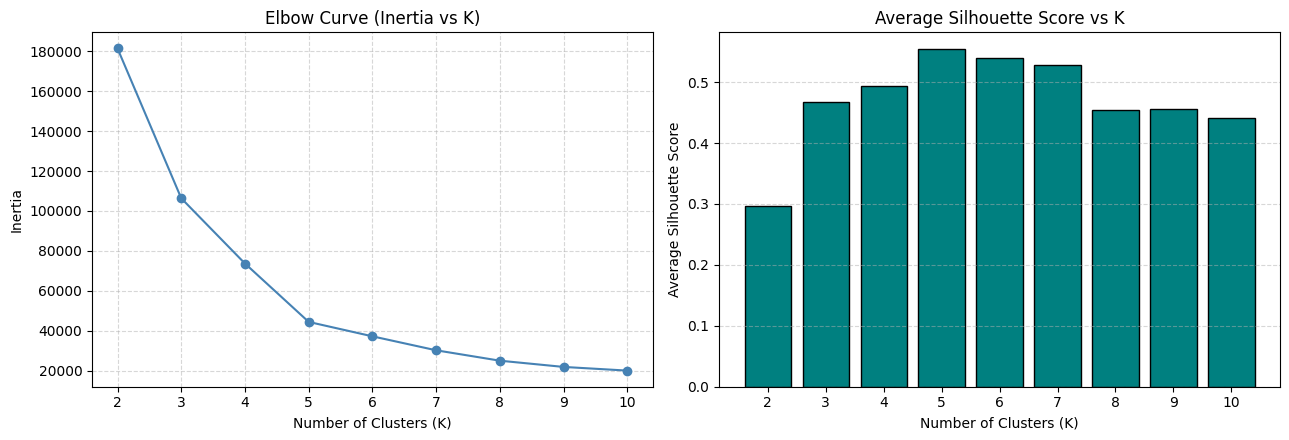

In [7]:
# YOUR CODE HERE
ks = list(range(2, 11))
inertias = []
silhouettes = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = km.fit_predict(X2)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X2, labels))

# Table of results
results_df = pd.DataFrame({
    'K': ks,
    'Inertia': np.round(inertias, 2),
    'Silhouette': np.round(silhouettes, 4)
})
print(results_df.to_string(index=False))

best_k = ks[int(np.argmax(silhouettes))]
print(f"\nBest K by highest Silhouette score: K = {best_k} ({max(silhouettes):.4f})")

# Side-by-side plots: Elbow curve and Silhouette bars
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Elbow Curve
axes[0].plot(ks, inertias, marker='o', color='steelblue')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Curve (Inertia vs K)')
axes[0].set_xticks(ks)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Silhouette Bars
axes[1].bar(ks, silhouettes, color='teal', edgecolor='k')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_title('Average Silhouette Score vs K')
axes[1].set_xticks(ks)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In the Elbow Curve on the left, inertia drops sharply from $K = 2$ (181363.60) down to $K = 5$ (44448.46), after which the line bends and flattens out slowly (37233.81 at $K = 6$), showing a clear elbow at $K = 5$. In the Average Silhouette Score bar chart on the right, the score rises steadily and reaches its highest peak at $K = 5$ (0.5539) before dropping for $K = 6$ (0.5398) and higher values. Both plots agree that 5 clusters provide the best balance of tight and well-separated customer groups.  

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [8]:
# YOUR CODE HERE
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = km5.fit_predict(X2)

def single_silhouette(X, labels, idx):
    point = X[idx]
    own_cluster = labels[idx]
    
    # Distances from this point to all points
    dists = np.sqrt(((X - point) ** 2).sum(axis=1))
    
    # a: mean distance to OTHER points in the same cluster
    same_mask = (labels == own_cluster) & (np.arange(len(X)) != idx)
    a = dists[same_mask].mean()
    
    # b: minimum mean distance to points in any other cluster
    other_clusters = [c for c in np.unique(labels) if c != own_cluster]
    b = min(dists[labels == c].mean() for c in other_clusters)
    
    # s: silhouette formula
    s = (b - a) / max(a, b)
    return a, b, s

a_0, b_0, s_0 = single_silhouette(X2, labels5, 0)
sk_s_0 = silhouette_samples(X2, labels5)[0]

print(f"Customer 1 (Row 0) -> Income: {X2[0,0]}, Spending: {X2[0,1]}, Cluster: {labels5[0]}")
print(f"Hand-calculated a : {a_0:.6f}")
print(f"Hand-calculated b : {b_0:.6f}")
print(f"Hand-calculated s : {s_0:.6f}")
print(f"sklearn s         : {sk_s_0:.6f}")
print(f"Difference        : {abs(s_0 - sk_s_0):.2e}")


Customer 1 (Row 0) -> Income: 15, Spending: 39, Cluster: 4
Hand-calculated a : 24.640442
Hand-calculated b : 42.265267
Hand-calculated s : 0.417005
sklearn s         : 0.417005
Difference        : 5.55e-17


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

(a)
Yes, they agree. The elbow curve bends sharply at $K = 5$ where inertia drops to 44448.46 (down from 73679.79 at $K = 4$) and then levels off slowly (37233.81 at $K = 6$). Similarly, the silhouette bar chart peaks at $K = 5$ with the highest score of 0.5539 (compared to 0.4932 at $K = 4$ and 0.5398 at $K = 6$), so both methods select $K = 5$.  

(b)
Customer 1 (row 0, Income: 15, Spending: 39, Cluster: 4) has a silhouette score of $s = 0.417005$ ($a = 24.640442$, $b = 42.265267$). Because $s$ is positive and well above $0$, this customer is correctly placed inside their own cluster (Low income, low spending), though positioned moderately near the upper border toward the neighboring middle cluster.

(c)
Inertia measures the sum of squared distances from every point to its assigned centroid, so it always decreases as $K$ increases (reaching 0 when $K = N$, where each customer is its own cluster). Choosing $K$ solely by the lowest inertia would always pick the maximum possible $K$, creating useless over-segmented groups instead of meaningful clusters.


---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [9]:
# YOUR CODE HERE
inertias_random = []
inertias_kpp = []

for seed in range(30):
    # Setting 1: init='random' with n_init=1
    km_rand = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed)
    km_rand.fit(X2)
    inertias_random.append(round(km_rand.inertia_, 1))
    
    # Setting 2: init='k-means++' with n_init=10
    km_kpp = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=seed)
    km_kpp.fit(X2)
    inertias_kpp.append(round(km_kpp.inertia_, 1))

print("Setting 1: init='random', n_init=1")
print(f"  Lowest Inertia  : {min(inertias_random)}")
print(f"  Highest Inertia : {max(inertias_random)}")
print(f"  Distinct Values : {len(set(inertias_random))} -> {sorted(set(inertias_random))}")

print("\nSetting 2: init='k-means++', n_init=10")
print(f"  Lowest Inertia  : {min(inertias_kpp)}")
print(f"  Highest Inertia : {max(inertias_kpp)}")
print(f"  Distinct Values : {len(set(inertias_kpp))} -> {sorted(set(inertias_kpp))}")

Setting 1: init='random', n_init=1
  Lowest Inertia  : 44448.5
  Highest Inertia : 91762.0
  Distinct Values : 14 -> [44448.5, 44454.5, 66532.0, 66674.4, 66698.1, 66733.4, 66790.3, 67789.3, 67818.5, 70096.4, 75036.5, 75582.7, 89897.5, 91762.0]

Setting 2: init='k-means++', n_init=10
  Lowest Inertia  : 44448.5
  Highest Inertia : 44448.5
  Distinct Values : 1 -> [44448.5]


**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a)
init='random', n_init=1: Produced 14 distinct final inertia values (lowest 44448.5, highest 91762.0).   init='k-means++', n_init=10: Produced 1 distinct final inertia value (44448.5) across all 30 seeds

(b)

K-Means is a greedy local-search algorithm that only moves centroids toward nearby points. Depending on where the initial centroids land, two centroids can get stuck inside one dense cluster while two separate clusters get merged together—causing the algorithm to converge to different local minima on the exact same dataset and same $K$.

(c)init='k-means++' chooses initial centroids that are spread far apart from each other instead of picking them purely at random, preventing multiple centroids from starting in the same cluster. Adding n_init=10 runs the algorithm 10 times with different smart starting positions and keeps only the run with the lowest inertia—eliminating all 13 suboptimal local minima (44454.5 up to 91762.0) and consistently finding the global best 44448.5 every time.


---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [10]:
# YOUR CODE HERE
# Prepare raw k$ and raw dollars copies
X_raw_k = df[['Age', 'Income']].values.copy()
X_raw_dollars = X_raw_k.copy().astype(float)
X_raw_dollars[:, 1] = X_raw_dollars[:, 1] * 1000  # Convert k$ to $

# Prepare scaled copies
X_scaled_k = StandardScaler().fit_transform(X_raw_k)
X_scaled_dollars = StandardScaler().fit_transform(X_raw_dollars)

# Fit KMeans (K=4) on all 4 versions
labels_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_raw_k)
labels_raw_dollars = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_raw_dollars)
labels_scaled_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_scaled_k)
labels_scaled_dollars = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_scaled_dollars)

# Compute ARI scores
ari_raw = adjusted_rand_score(labels_raw_k, labels_raw_dollars)
ari_scaled = adjusted_rand_score(labels_scaled_k, labels_scaled_dollars)

print(f"ARI (raw k$ vs raw dollars)       : {ari_raw:.4f}")
print(f"ARI (scaled k$ vs scaled dollars) : {ari_scaled:.4f}")


ARI (raw k$ vs raw dollars)       : 0.4897
ARI (scaled k$ vs scaled dollars) : 1.0000


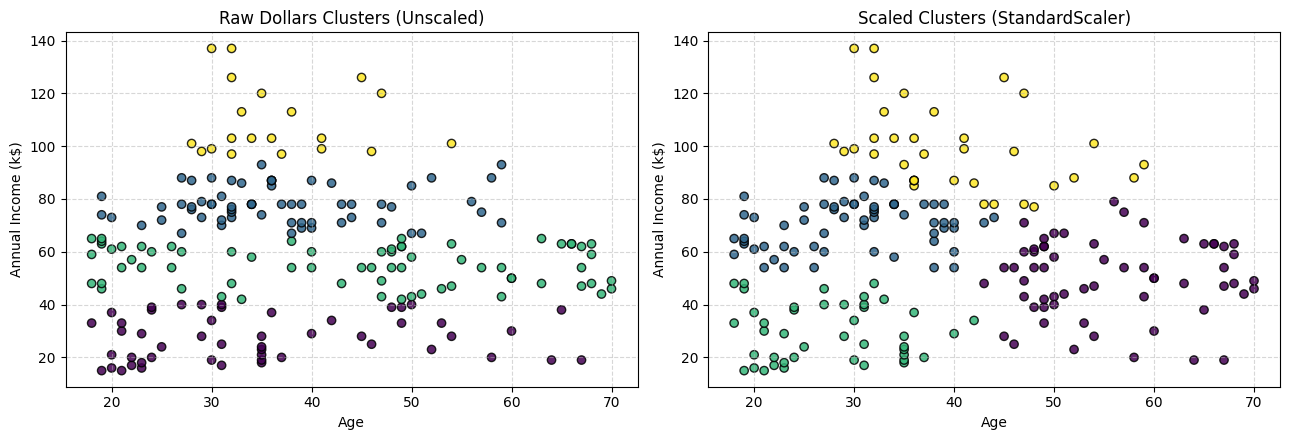

In [11]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left plot: Raw-dollar clusters
axes[0].scatter(X_raw_k[:, 0], X_raw_k[:, 1], c=labels_raw_dollars, cmap='viridis', edgecolors='k', alpha=0.85)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Annual Income (k$)')
axes[0].set_title('Raw Dollars Clusters (Unscaled)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right plot: Scaled clusters
axes[1].scatter(X_raw_k[:, 0], X_raw_k[:, 1], c=labels_scaled_dollars, cmap='viridis', edgecolors='k', alpha=0.85)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Annual Income (k$)')
axes[1].set_title('Scaled Clusters (StandardScaler)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In the left plot (Raw Dollars Clusters), converting Income to dollars (15,000–137,000) causes income numbers to completely dominate Euclidean distance over Age (18–70), slicing customers into horizontal income bands. In the right plot (Scaled Clusters), applying StandardScaler puts both Age and Income on equal footing (mean = 0, std = 1). As a result, the scaled plot forms natural 2D clusters that group customers by both age and income together rather than income alone.

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a)
(a) When only the unit of Income changed from k$ (15–137) to dollars (15,000–137,000), the unscaled cluster assignments changed dramatically (ARI = 0.4897 instead of 1.0). In the Euclidean distance formula $d = \sqrt{(Age_1 - Age_2)^2 + (Income_1 - Income_2)^2}$, squared dollar differences are in the millions while Age differences are only a few tens—so Income completely dominates the distance and forces horizontal income-only bands. StandardScaler fixed this by transforming both features to $z$-scores (mean 0, standard deviation 1), giving Age and Income equal weight regardless of measurement units (ARI = 1.0000)

(b)
i wil use rule: Always scale features with StandardScaler whenever columns have different units or noticeably different numeric ranges (such as age in years vs. income in dollars). Only skip scaling if all features already share the exact same unit and scale and you intentionally want larger raw differences to carry more weight.


---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

--- Original Data (200 customers) ---
  Group 1 (Cluster 2): Size =  22 | Centroid = (Income:  25.73, Spending:  79.36)
  Group 2 (Cluster 4): Size =  23 | Centroid = (Income:  26.30, Spending:  20.91)
  Group 3 (Cluster 0): Size =  81 | Centroid = (Income:  55.30, Spending:  49.52)
  Group 4 (Cluster 1): Size =  39 | Centroid = (Income:  86.54, Spending:  82.13)
  Group 5 (Cluster 3): Size =  35 | Centroid = (Income:  88.20, Spending:  17.11)

--- With Extreme Customer (201 customers) ---
  Group 1 (Cluster 2): Size =  23 | Centroid = (Income:  26.30, Spending:  20.91)
  Group 2 (Cluster 0): Size = 100 | Centroid = (Income:  48.26, Spending:  56.48)
  Group 3 (Cluster 3): Size =  39 | Centroid = (Income:  86.54, Spending:  82.13)
  Group 4 (Cluster 4): Size =  38 | Centroid = (Income:  87.00, Spending:  18.63)
  Group 5 (Cluster 1): Size =   1 | Centroid = (Income: 400.00, Spending:  99.00)


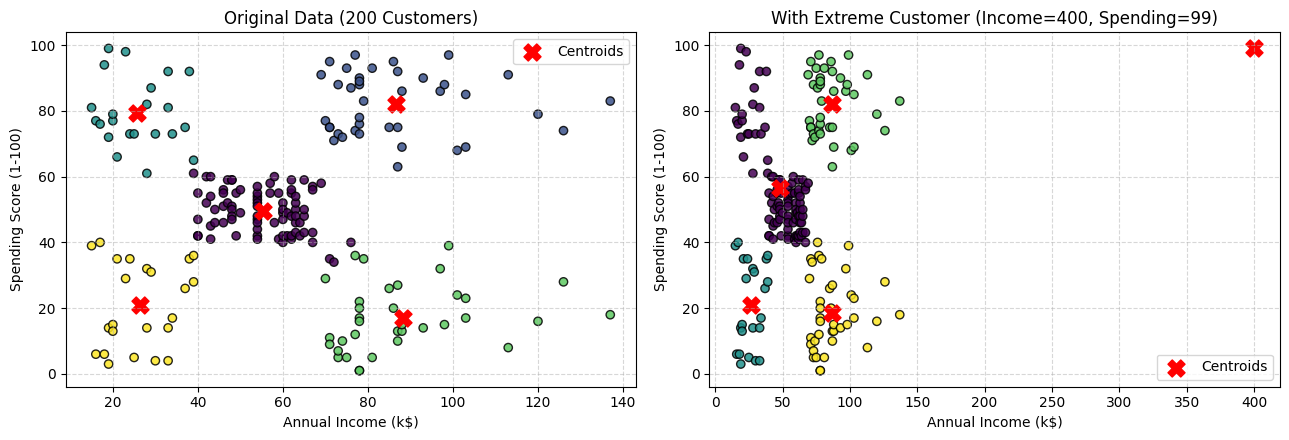

In [12]:
# YOUR CODE HERE
# Add one extreme customer: Income = 400, Spending = 99
X2_outlier = np.vstack([X2, [[400, 99]]])

# Fit KMeans (K=5) without and with the outlier
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_outlier)

def print_cluster_summary(name, labels, centers):
    # Sort clusters by Income (column 0)
    order = np.argsort(centers[:, 0])
    print(f"--- {name} ---")
    for idx, c_id in enumerate(order):
        size = np.sum(labels == c_id)
        inc, spd = centers[c_id]
        print(f"  Group {idx+1} (Cluster {c_id}): Size = {size:3d} | Centroid = (Income: {inc:6.2f}, Spending: {spd:6.2f})")

print_cluster_summary("Original Data (200 customers)", km_clean.labels_, km_clean.cluster_centers_)
print()
print_cluster_summary("With Extreme Customer (201 customers)", km_out.labels_, km_out.cluster_centers_)

# Draw side-by-side scatter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left plot: Original 200 customers
axes[0].scatter(X2[:, 0], X2[:, 1], c=km_clean.labels_, cmap='viridis', edgecolors='k', alpha=0.85)
axes[0].scatter(km_clean.cluster_centers_[:, 0], km_clean.cluster_centers_[:, 1], c='red', marker='X', s=150, label='Centroids')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].set_title('Original Data (200 Customers)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right plot: With outlier
axes[1].scatter(X2_outlier[:, 0], X2_outlier[:, 1], c=km_out.labels_, cmap='viridis', edgecolors='k', alpha=0.85)
axes[1].scatter(km_out.cluster_centers_[:, 0], km_out.cluster_centers_[:, 1], c='red', marker='X', s=150, label='Centroids')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].set_title('With Extreme Customer (Income=400, Spending=99)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In the left plot (Original Data), the 5 red centroids sit neatly at the centers of the 5 natural customer groups. In the right plot (With Extreme Customer), adding just one extreme outlier (Income = 400, Spending = 99) pulls one centroid all the way out to (400.00, 99.00) as a cluster of size 1. Because $K$ stays fixed at 5, dedicating a centroid to that single outlier forces the Low income, high spending group (Size = 22) and the central group (Size = 81) to merge into one big cluster of Size = 100.

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [13]:
# YOUR CODE HERE
# Distances of the 200 real customers to their nearest centroid
dists_real = km_clean.transform(X2).min(axis=1)

# Distance of the extra customer to its nearest centroid
dist_extra = km_clean.transform([[400, 99]]).min(axis=1)[0]

# Threshold: mean + 3 * std from the 200 real customers
threshold = dists_real.mean() + 3 * dists_real.std()

# Check flags
extra_flagged = dist_extra > threshold
real_flagged_idx = np.where(dists_real > threshold)[0]

print(f"Mean distance (200 real) : {dists_real.mean():.2f}")
print(f"Std distance (200 real)  : {dists_real.std():.2f}")
print(f"Threshold (mean + 3*std) : {threshold:.2f}")
print(f"Extra customer distance  : {dist_extra:.2f} -> Flagged? {extra_flagged}")
print(f"Real customers flagged   : {len(real_flagged_idx)} customer(s) at row index {real_flagged_idx.tolist()}")

if len(real_flagged_idx) > 0:
    for r in real_flagged_idx:
        print(f"  Row {r}: Income={X2[r,0]}, Spending={X2[r,1]}, Distance={dists_real[r]:.2f}")

Mean distance (200 real) : 13.02
Std distance (200 real)  : 7.26
Threshold (mean + 3*std) : 34.80
Extra customer distance  : 313.92 -> Flagged? True
Real customers flagged   : 4 customer(s) at row index [196, 197, 198, 199]
  Row 196: Income=126, Spending=28, Distance=39.34
  Row 197: Income=126, Spending=74, Distance=40.29
  Row 198: Income=137, Spending=18, Distance=48.81
  Row 199: Income=137, Spending=83, Distance=50.47


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

(a)
Adding the single extreme customer (Income = 400, Spending = 99) pulled one centroid directly onto itself, forming a singleton cluster of Size = 1 at (400.00, 99.00). Because $K$ was fixed at 5, using a centroid for that one outlier forced two genuine clusters—the Low income, high spending group (Size = 22, centroid (25.73, 79.36)) and the central group (Size = 81, centroid (55.30, 49.52))—to merge into a single large cluster of Size = 100 with centroid (48.26, 56.48), while the high-income low-spending centroid also shifted slightly from (88.20, 17.11) (Size = 35) to (87.00, 18.63) (Size = 38). 

(b)
Yes, the mean + 3 * std rule (threshold = 34.80) caught the extra customer easily (distance = 313.92 > 34.80). It also flagged 4 real customers (rows 196, 197, 198, 199 with Income = 126 or 137 and distances 39.34 to 50.47). These 4 real customers are not data errors—they are simply legitimate, unusually wealthy customers sitting at the outer edges of the valid high-income segments.


(c)
Two ways to deal with outliers: (1) Winsorize or cap extreme feature values at a reasonable upper percentile before clustering, or (2) use a more outlier-resistant clustering algorithm such as K-Medoids or DBSCAN (which labels isolated extreme points as noise instead of forcing them into clusters).

Risk of simply deleting them: Deleting flagged points without inspecting them first can erase real, high-value VIP customers (such as rows 196–199 earning $126k–$137k), causing the business to overlook its wealthiest customer base


---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [14]:
# YOUR CODE HERE
# 1. Fit final model (K=5) and add Cluster column
final_km = KMeans(n_clusters=5, n_init=10, random_state=SEED)
df['Cluster'] = final_km.fit_predict(df[['Income', 'Spending']].values)

# 2. Show size and mean Age, Income, Spending of each cluster
profile = df.groupby('Cluster')[['Age', 'Income', 'Spending']].mean().round(2)
profile['Size'] = df['Cluster'].value_counts().sort_index()
profile = profile[['Size', 'Age', 'Income', 'Spending']]
print(profile)

# 3. Map short segment names to Cluster IDs and store in Segment column
segment_names = {
    0: 'Medium income, medium spending',
    1: 'High income, high spending',
    2: 'Low income, high spending',
    3: 'High income, low spending',
    4: 'Low income, low spending'
}
df['Segment'] = df['Cluster'].map(segment_names)
print("\nSegment Counts:\n", df['Segment'].value_counts())


         Size    Age  Income  Spending
Cluster                               
0          81  42.72   55.30     49.52
1          39  32.69   86.54     82.13
2          22  25.27   25.73     79.36
3          35  41.11   88.20     17.11
4          23  45.22   26.30     20.91

Segment Counts:
 Segment
Medium income, medium spending    81
High income, high spending        39
High income, low spending         35
Low income, low spending          23
Low income, high spending         22
Name: count, dtype: int64


**Segment names and actions** (one line per cluster)

| Cluster | Segment name | Marketing action |
|---|---|---|
| 0 | Medium income,medium spending|Send loyalty reward points and seasonal bundle deals to encourage repeat visits |
| 1 |High income,hig spending |Offer VIP early access,luxury,membership and exclusive new arrival previews |
| 2 |Low income,high spending |Promote buy now pay later options,flash seales and trendy affordable collections |
| 3 |High income,low spending |Run targeted quality focused campaingns and personlized discounts to unlock untapped spending |
| 4 |Low income,low spending |Advertise budget freindly clearance items,value packs and essential discount coupans |

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [15]:
# YOUR CODE HERE
# 1. Save customer_segments.csv with exact required columns
cols_to_save = ['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']
df[cols_to_save].to_csv('customer_segments.csv', index=False)
print("Saved customer_segments.csv successfully! Shape:", df[cols_to_save].shape)
print(df[cols_to_save].head())

Saved customer_segments.csv successfully! Shape: (200, 7)
   CustomerID  Age  Gender  Income  Spending  Cluster  \
0           1   19    Male      15        39        4   
1           2   21    Male      15        81        2   
2           3   20  Female      16         6        4   
3           4   23  Female      16        77        2   
4           5   31  Female      17        40        4   

                     Segment  
0   Low income, low spending  
1  Low income, high spending  
2   Low income, low spending  
3  Low income, high spending  
4   Low income, low spending  


**Executive Summary** (4–6 lines)

*Your summary here.*
We segmented the 200 mall customers into $K = 5$ clusters using Income and Spending, backed by a clear elbow bend (inertia = 44448.46) and the highest average silhouette score (0.5539). The five customer segments are Medium income, medium spending (81 customers), High income, high spending (39), High income, low spending (35), Low income, low spending (23), and Low income, high spending (22). Because Income (15–137) and Spending (1–99) sit on comparable numeric scales, raw values were used for the final fit (whereas mixing Age and dollar Income required StandardScaler to prevent unit distortion), and all 200 real rows were retained without removing natural high-income tail customers. One key limitation is that K-Means uses Euclidean distance on only two features, assuming spherical clusters and ignoring Age and Gender differences within segments.   

---

### Before you submit
- [ ] Restart the kernel and **Run All**: the notebook runs top to bottom without errors.
- [ ] Every table and plot has 1–3 lines of interpretation below it.
- [ ] All questions are answered with your own numbers.
- [ ] Student Information block is filled in.
- [ ] Notebook and `customer_segments.csv` are pushed to your GitHub repository.